<a href="https://colab.research.google.com/github/kfartem434-png/MN_Kapusta/blob/main/%D0%9B%D0%912_3_%D0%9A%D0%B0%D0%BF%D1%83%D1%81%D1%82%D0%B0_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#!pip install pandas --upgrade

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

In [5]:
print(np.__version__)
print(pd.__version__)

2.1.3
2.2.3


In [6]:
url = "https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C"

html = requests.get(url,headers={"user-agent": "Chrome/154.0.8037.98"}).content
tables = pd.read_html(html)

len(tables)

70

In [7]:
num_columns = 9
new_tables = []

for table in tables:
  if len(table.columns) == num_columns:
    new_tables.append(table)

len(new_tables)

2

In [8]:
new_tables

[               Регіон   1950   1960   1970  1990  2000  2012 2014 2019
 0                Крим  230.0  206.0  160.0   130    73   126    —    —
 1           Вінницька  224.0  192.0  142.0   124    84   112  109   76
 2           Волинська  247.0  250.0  179.0   153   112   148  141  101
 3    Дніпропетровська  204.0  204.0  151.0   123    71   112  111   71
 4            Донецька  271.0  214.0  140.0   109    61    98   82    —
 5         Житомирська  261.0  223.0  159.0   129    89   122  120   79
 6        Закарпатська  314.0  273.0  207.0   168   115   151  146  104
 7          Запорізька  219.0  197.0  150.0   124    71   106  106   68
 8   Івано-Франківська  243.0  248.0  182.0   155   103   124  122   88
 9            Київська  204.0  189.0  156.0   123    73   122  121   80
 10     Кіровоградська  216.0  171.0  145.0   126    79   110  108   68
 11          Луганська  262.0  235.0  144.0   116    62    96   51    —
 12          Львівська  234.0  240.0  171.0   140    91   119  1

In [9]:
df = new_tables[0]
print(df.shape)
print(df.columns.values)
df.head(10)

(28, 9)
['Регіон' '1950' '1960' '1970' '1990' '2000' '2012' '2014' '2019']


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,230.0,206.0,160.0,130,73,126,—,—
1,Вінницька,224.0,192.0,142.0,124,84,112,109,76
2,Волинська,247.0,250.0,179.0,153,112,148,141,101
3,Дніпропетровська,204.0,204.0,151.0,123,71,112,111,71
4,Донецька,271.0,214.0,140.0,109,61,98,82,—
5,Житомирська,261.0,223.0,159.0,129,89,122,120,79
6,Закарпатська,314.0,273.0,207.0,168,115,151,146,104
7,Запорізька,219.0,197.0,150.0,124,71,106,106,68
8,Івано-Франківська,243.0,248.0,182.0,155,103,124,122,88
9,Київська,204.0,189.0,156.0,123,73,122,121,80


Датафрейм має розмірність 28 рядків та 9 стовпців.

Стовпці зберігають такі дані:

**Регіон**: регіон у якому визначається коефіцієнт народжуваності;

**Інші стовпці**: роки у яких визначається коефіцієнт народжуваності, від 1950 р. до 2000 р. з інтервалами в 10 років та без 1980 р., та 2012, 2014, 2019 роки.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Регіон  28 non-null     object 
 1   1950    26 non-null     float64
 2   1960    27 non-null     float64
 3   1970    27 non-null     float64
 4   1990    28 non-null     int64  
 5   2000    28 non-null     int64  
 6   2012    28 non-null     int64  
 7   2014    28 non-null     object 
 8   2019    28 non-null     object 
dtypes: float64(3), int64(3), object(3)
memory usage: 2.1+ KB


In [11]:
df.loc[df.duplicated()]

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019


In [12]:
df.loc[df.duplicated("Регіон")]

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019


In [13]:
df.isna().sum()

,0
Регіон,0
1950,2
1960,1
1970,1
1990,0
2000,0
2012,0
2014,0
2019,0


Датафрейм не має дуплікатів, але має пропуски в стовпцях 1950, 1960, 1970 років.

In [14]:
def is_number(string: str,dec_point: str = ".") -> bool:
  sign = False
  decimal = False
  iterator = iter(string)
  char = next(iterator)
  if char in ("-","+"):
    sign = True
  elif char == dec_point:
    decimal = True
  elif not char.isnumeric():
    return False
  for char in iterator:
    if char in ("-","+"):
      return False
    elif char == dec_point:
      if not decimal:
        decimal = True
      else:
        return False
    elif not char.isnumeric():
      return False
  return True

df.iloc[:,1:] = df.iloc[:,1:].map(lambda x: np.nan if not is_number(str(x)) else x)
clean = df.iloc[:,1:].astype("float64") / 10
clean.insert(0,df.columns[0],df.iloc[:,0])
clean.head()

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,NaN,NaN
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,NaN


In [15]:
clean.isna().sum()

,0
Регіон,0
1950,2
1960,1
1970,1
1990,0
2000,0
2012,0
2014,2
2019,4


Після очищення датасету можна побачити, що пропуски також наявні в стовпцях 2014 та 2019 років.

In [16]:
clean.describe()

,1950,1960,1970,1990,2000,2012,2014,2019
count,26.000000,27.000000,27.000000,28.000000,28.000000,28.000000,26.000000,24.000000
mean,23.092308,20.748148,15.585185,13.042857,8.207143,11.646429,11.142308,8.020833
std,2.822045,2.936032,1.870357,1.527872,1.556808,1.636274,2.011601,1.450331
min,18.600000,16.300000,12.700000,10.800000,6.100000,9.400000,5.100000,6.000000
25%,21.150000,18.650000,14.400000,12.225000,7.075000,10.450000,10.225000,6.800000
50%,22.600000,20.400000,15.200000,12.600000,7.850000,11.450000,11.150000,7.900000
75%,24.600000,22.050000,16.300000,14.050000,8.950000,12.250000,12.100000,8.800000
max,31.400000,27.300000,20.700000,16.800000,11.800000,15.900000,14.800000,11.000000


З опису числових даних датасету можна побачити:

Коефіцієнт народжуваності був мінімальним у 2014 році;

У середньому по регіонам, мінімальним коефіцієнт народжуваності був у 2019 році;

Максимальним, по регіонах і окремих областях, коефіцієнт народжуваності був у 1950 році;

Максимальна варіація коефіцієнта народжуваності по регіонах була в 1960 році.

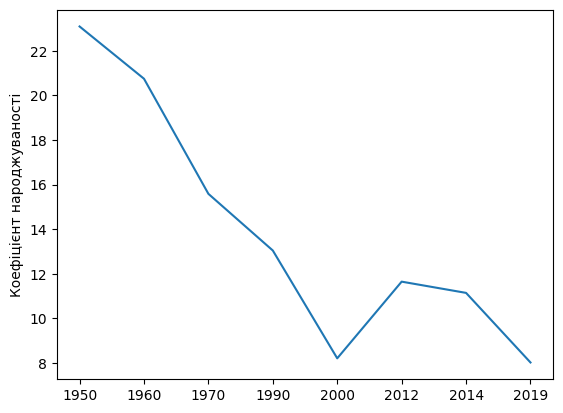

Коефіцієнт кореляції: 

 -0.9264443212168696



In [17]:
mean_birth_coef_by_years = clean.iloc[:,1:].mean(axis=0)
mean_birth_coef_by_years.plot(kind="line")
plt.ylabel("Коефіцієнт народжуваності")
plt.show()
print(
  "Коефіцієнт кореляції: \n\n",
  pd.Series(mean_birth_coef_by_years.values).corr(pd.Series(mean_birth_coef_by_years.index.values)),
  end="\n\n"
)

З графіку та коефіцієнта кореляції видно, що спостерігається зменшення коефіцієнта народжуваності з часом.

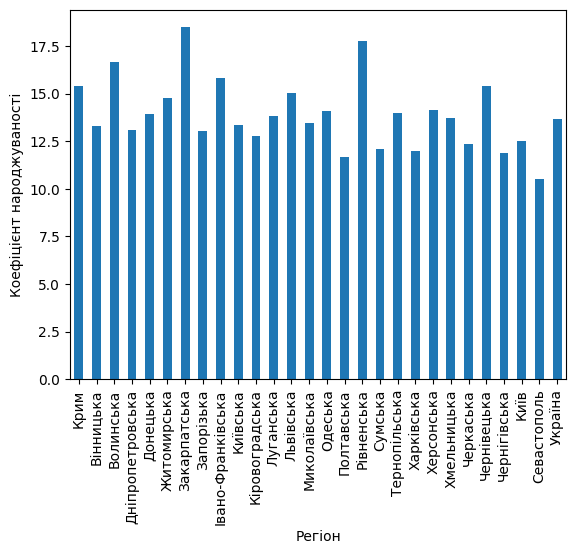

In [19]:
mean_birth_coef_by_region = pd.DataFrame(clean.iloc[:,1:].mean(axis=1))
mean_birth_coef_by_region.insert(0,clean.columns[0],clean[clean.columns[0]])
mean_birth_coef_by_region.plot(kind="bar",x="Регіон",y=0,legend=False)
plt.ylabel("Коефіцієнт народжуваності")
plt.show()

Найвищий середній коефіцієнт народжуваності має Закарпатський регіон, коефіцієнт по Україні приблизно 14 проміле.

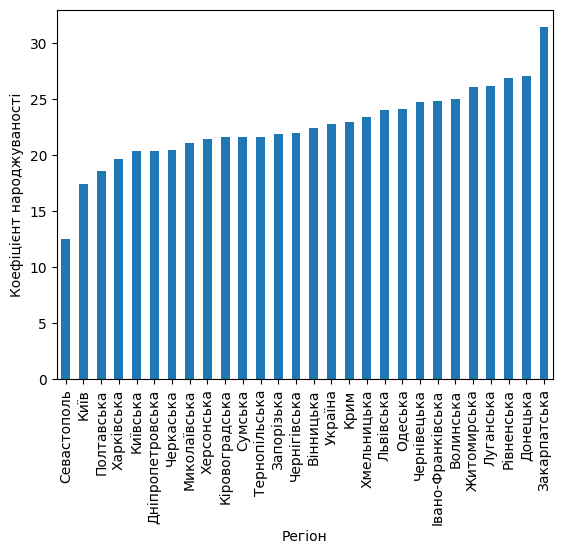

In [30]:
max_birth_coef_by_region = pd.DataFrame(clean.iloc[:,1:].max(axis=1)).sort_values(0,ascending=True)
max_birth_coef_by_region.insert(0,clean.columns[0],clean[clean.columns[0]])
max_birth_coef_by_region.plot(kind="bar",x="Регіон",legend=False)
plt.ylabel("Коефіцієнт народжуваності")
plt.show()

Як видно з графіку, найвищий коефіцієнт народжуваності за весь час має Закарпатський регіон, найнижчий з максимумів -- Севастопольский регіон.

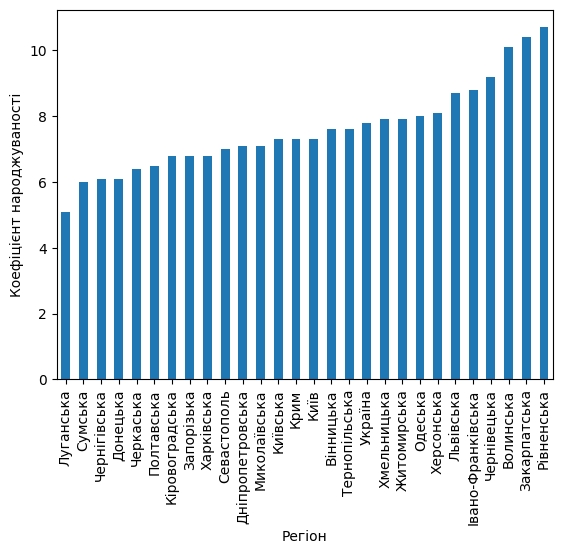

In [29]:
min_birth_coef_by_region = pd.DataFrame(clean.iloc[:,1:].min(axis=1)).sort_values(0,ascending=True)
min_birth_coef_by_region.insert(0,clean.columns[0],clean[clean.columns[0]])
min_birth_coef_by_region.plot(kind="bar",x="Регіон",legend=False)
plt.ylabel("Коефіцієнт народжуваності")
plt.show()

Доповнюючи попередній графік -- мінімальний коефіцієнт народжуваності за весь час має Луганський регіон, максимальний коефіцієнт з мінімумів має Рівненський регіон.

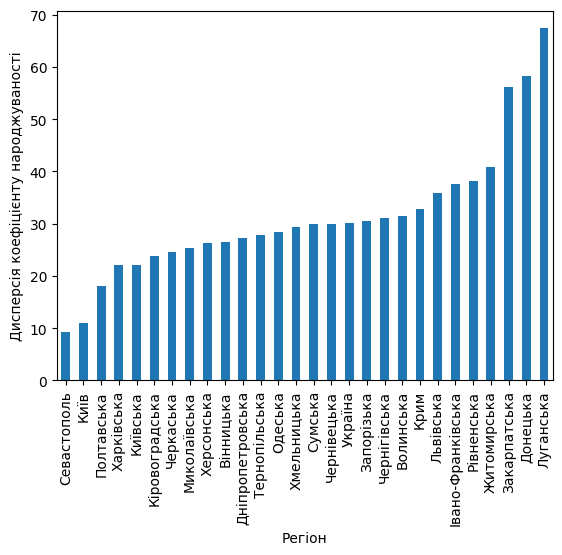

In [42]:
var_birth_coef_by_region = pd.DataFrame(clean.iloc[:,1:].var(axis=1))
var_birth_coef_by_region.insert(0,clean.columns[0],clean[clean.columns[0]])
var_birth_coef_by_region.sort_values(0,ascending=True,inplace=True)
var_birth_coef_by_region.plot(kind="bar",x="Регіон",legend=False)
plt.ylabel("Дисперсія коефіцієнту народжуваності")
plt.show()

З цього графіку видно, що найвищі показники дисперсії мають Закарпатська, Донецька та Луганська області.